# Random Forest EcoPlant — latih dengan gambar sendiri

Struktur folder yang diharapkan: satu folder per kelas, isi gambarnya bebas (JPEG/PNG).

```
folder_gambar/
├── cordana/
├── healthy/
├── pestalotiopsis/
└── sigatoka/
```

Nama folder menjadi label. Notebook ini memakai split `train/val/test` bila ketiganya ada;
kalau tidak, gambar dibagi sendiri 70/15/15 secara stratified (seed 42).

Alurnya mengikuti tutorial DataCamp: rekayasa fitur, membagi data, melatih model,
tuning hyperparameter, lalu menilai kinerja (akurasi, precision, recall, confusion
matrix, feature importance).

Aplikasi EcoPlant mengunci 4 kelas: Cordana, Healthy, Pestalotiopsis, Sigatoka. Model dengan
kelas berbeda tetap bisa dilatih di sini, tetapi akan ditolak aplikasi saat validasi label.

## Memakai gambar dari HP atau Google Colab

Di Colab, unggah zip berisi folder kelas lalu ekstrak:

```python
from google.colab import files
files.upload()          # pilih gambar.zip
!unzip -q gambar.zip -d /content/gambar
```

Kemudian isi `DATA_DIR_OVERRIDE = "/content/gambar"` pada sel berikut.

In [15]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from scipy.stats import randint
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import make_pipeline

SEED = 42
IMAGE_SIZE = (64, 64)
BINS = 16
N_ITER = 10
CV_FOLDS = 5
APP_CLASSES = ["Cordana", "Healthy", "Pestalotiopsis", "Sigatoka"]

DATA_DIR_OVERRIDE = ""      # contoh: "/content/gambar" atau "D:/dataset/daun"
OUTPUT_DIR_OVERRIDE = ""    # kosong = training/artifacts_rf_custom
COPY_TO_ASSETS = True       # salin forest.json ke ecoplant/assets/models

In [16]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ROOT = Path.cwd()
if not (ROOT / "training").is_dir() and (ROOT.parent / "training").is_dir():
    ROOT = ROOT.parent

if DATA_DIR_OVERRIDE.strip():
    DATA_DIR = Path(DATA_DIR_OVERRIDE).expanduser()
elif (ROOT / "training" / "dataset_retrain").is_dir():
    DATA_DIR = ROOT / "training" / "dataset_retrain"
else:
    raise FileNotFoundError("Folder gambar tidak ditemukan. Isi DATA_DIR_OVERRIDE.")

OUTPUT_DIR = (
    Path(OUTPUT_DIR_OVERRIDE).expanduser()
    if OUTPUT_DIR_OVERRIDE.strip()
    else ROOT / "training" / "artifacts_rf_custom"
)
print("Dataset:", DATA_DIR.resolve())
print("Output :", OUTPUT_DIR.resolve())

Dataset: C:\PBL-KEL4_TI3C_SEM5\training\dataset_retrain
Output : C:\PBL-KEL4_TI3C_SEM5\training\artifacts_rf_custom


### 1. Memuat dataset

Gambar daun dibaca dari folder `dataset_retrain`. Nama folder kelas dipetakan ke empat
label aplikasi (Cordana, Healthy, Pestalotiopsis, Sigatoka) supaya urutan label model
sama dengan yang dipakai aplikasi.

### 2. Membagi data

Notebook memakai split `train/val/test` yang tersedia; bila tidak ada, data dibagi
70/15/15 secara stratified dengan seed 42 agar proporsi tiap kelas tetap terjaga.
Jumlah gambar per split dicetak untuk memeriksa komposisi kelas.

In [17]:
def collect(folder):
    return [
        {"path": path, "label": path.parent.name.capitalize()}
        for path in sorted(folder.rglob("*"))
        if path.is_file() and path.suffix.lower() in EXTENSIONS
    ]

if all((DATA_DIR / name).is_dir() for name in ("train", "val", "test")):
    parts = {name: pd.DataFrame(collect(DATA_DIR / name)) for name in ("train", "val", "test")}
    print("Memakai split yang sudah ada di", DATA_DIR)
else:
    frame = pd.DataFrame(collect(DATA_DIR))
    if frame.empty:
        raise ValueError("Tidak ada gambar di " + str(DATA_DIR))
    train_val, test = train_test_split(
        frame, test_size=0.15, stratify=frame["label"], random_state=SEED
    )
    train, val = train_test_split(
        train_val, test_size=0.1765, stratify=train_val["label"], random_state=SEED
    )
    parts = {"train": train, "val": val, "test": test}
    print("Membagi sendiri 70/15/15 secara stratified.")

names = set().union(*[set(part["label"]) for part in parts.values()])
labels = [c for c in APP_CLASSES if c in names] + sorted(names - set(APP_CLASSES))
if labels != APP_CLASSES:
    print("PERINGATAN: label", labels, "berbeda dari kelas aplikasi", APP_CLASSES)

for name, part in parts.items():
    print(f"{name:5s} {len(part):4d} gambar | {part['label'].value_counts().to_dict() if len(part) else {}}")

Memakai split yang sudah ada di c:\PBL-KEL4_TI3C_SEM5\training\dataset_retrain
train  779 gambar | {'Sigatoka': 341, 'Pestalotiopsis': 168, 'Cordana': 153, 'Healthy': 117}
val    275 gambar | {'Sigatoka': 117, 'Pestalotiopsis': 62, 'Cordana': 56, 'Healthy': 40}
test   267 gambar | {'Sigatoka': 115, 'Pestalotiopsis': 59, 'Cordana': 53, 'Healthy': 40}


### 3. Rekayasa fitur

Setiap gambar diperkecil ke 64x64 dengan interpolasi nearest, lalu diubah menjadi
histogram RGB 16 bin per kanal ditambah histogram hue 16 bin, sehingga menghasilkan
64 fitur ternormalisasi 0-1. Proses ini identik dengan `copyResize` dan histogram di
sisi Dart supaya prediksi di HP sama dengan saat latihan.

In [18]:
def hue_histogram(pixels):
    rgb = pixels.astype(np.int32)
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maxc = rgb.max(axis=2)
    delta = (maxc - rgb.min(axis=2)).astype(np.float64)
    with np.errstate(divide="ignore", invalid="ignore"):
        hue = np.where(
            maxc == r,
            ((g - b) / delta) % 6,
            np.where(maxc == g, (b - r) / delta + 2, (r - g) / delta + 4),
        )
    hue[delta == 0] = 0
    bins = np.minimum((hue / 6 * BINS).astype(np.int64), BINS - 1)
    return np.bincount(bins.ravel(), minlength=BINS) * BINS / maxc.size

def leaf_features(image):
    pixels = np.asarray(ImageOps.exif_transpose(image).convert("RGB"))
    rows = np.arange(IMAGE_SIZE[1]) * pixels.shape[0] // IMAGE_SIZE[1]
    cols = np.arange(IMAGE_SIZE[0]) * pixels.shape[1] // IMAGE_SIZE[0]
    pixels = pixels[np.ix_(rows, cols)]
    scaled = pixels.astype(np.float32) / 255.0
    return np.concatenate([
        np.histogram(scaled[:, :, ch], bins=BINS, range=(0, 1), density=True)[0]
        for ch in range(3)
    ] + [hue_histogram(pixels)])

def features_for(frame):
    X, y, skipped = [], [], 0
    for row in frame.itertuples():
        try:
            with Image.open(row.path) as image:
                X.append(leaf_features(image))
        except (OSError, ValueError):
            skipped += 1
            continue
        y.append(labels.index(row.label))
    if skipped:
        print(f"{skipped} gambar dilewati karena tidak bisa dibaca.")
    return np.asarray(X), np.asarray(y)

X_train, y_train = features_for(parts["train"])
X_val, y_val = features_for(parts["val"])
X_test, y_test = features_for(parts["test"])
print("Train", X_train.shape, "| Val", X_val.shape, "| Test", X_test.shape)

c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
c:\PBL-KEL4_TI3C_SEM5\.venv\Lib\site-packages\PIL\JpegImagePlugin.py:874: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Train (779, 64) | Val (275, 64) | Test (267, 64)


### 4. Melatih model

`RandomForestClassifier` dengan `class_weight="balanced_subsample"` dilatih pada data
latih agar kelas minoritas (Healthy) tidak tenggelam oleh kelas mayoritas (Sigatoka).

### 5. Tuning hyperparameter

`RandomizedSearchCV` mencoba 10 kombinasi `n_estimators`, `max_depth`,
`min_samples_split`, dan `min_samples_leaf` dengan 5-fold cross-validation pada data
latih, lalu memilih kombinasi dengan akurasi terbaik. Hasilnya dicetak di bawah sel ini.

In [19]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    ),
)

param_dist = {
    "randomforestclassifier__n_estimators": randint(100, 500),
    "randomforestclassifier__max_depth": randint(3, 15),
    "randomforestclassifier__min_samples_split": randint(2, 10),
    "randomforestclassifier__min_samples_leaf": randint(1, 5),
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=CV_FOLDS,
    scoring="accuracy",
    n_jobs=-1,
    random_state=SEED,
)
search.fit(X_train, y_train)

pipeline = search.best_estimator_
print("Hyperparameter terbaik:", search.best_params_)
print("Akurasi CV terbaik:", round(search.best_score_, 4))
print("Jumlah pohon:", len(pipeline.named_steps["randomforestclassifier"].estimators_))

Hyperparameter terbaik: {'randomforestclassifier__max_depth': 14, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__n_estimators': 413}
Akurasi CV terbaik: 0.819
Jumlah pohon: 413


### 6. Evaluasi model

Model terbaik diuji pada data val dan test memakai akurasi serta classification report
(precision, recall, f1 per kelas). Angka tiap kelas dicetak di bawah sel ini.

### 7. Confusion matrix

Matriks konfusi memperlihatkan kelas mana yang paling sering tertukar, sehingga
kelemahan model per kelas terlihat jelas dan bukan hanya satu angka akurasi.

### 8. Feature importance

Skor kepentingan fitur dari model menunjukkan bin warna mana yang paling menentukan
keputusan, sehingga dasar klasifikasi bisa dijelaskan dan bukan sekadar kotak hitam.


[val] accuracy = 0.8145
                precision    recall  f1-score   support

       Cordana       0.92      0.88      0.90        56
       Healthy       0.70      0.70      0.70        40
Pestalotiopsis       0.67      0.73      0.70        62
      Sigatoka       0.89      0.87      0.88       117

      accuracy                           0.81       275
     macro avg       0.80      0.79      0.79       275
  weighted avg       0.82      0.81      0.82       275


[test] accuracy = 0.8427
                precision    recall  f1-score   support

       Cordana       0.90      0.85      0.87        53
       Healthy       0.72      0.85      0.78        40
Pestalotiopsis       0.81      0.78      0.79        59
      Sigatoka       0.88      0.87      0.88       115

      accuracy                           0.84       267
     macro avg       0.83      0.84      0.83       267
  weighted avg       0.85      0.84      0.84       267

Accuracy : 0.8427
Precision (macro): 0.8288
Rec

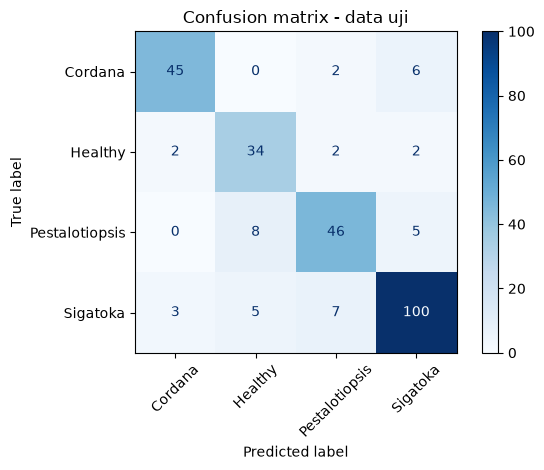

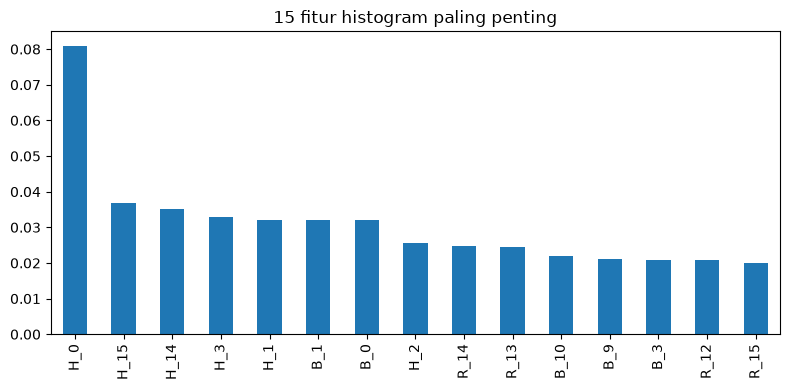

In [20]:
test_predictions = pipeline.predict(X_test)
cm = confusion_matrix(y_test, test_predictions, labels=range(len(labels)))

for name, X, y in (("val", X_val, y_val), ("test", X_test, y_test)):
    predictions = pipeline.predict(X)
    print(f"\n[{name}] accuracy = {accuracy_score(y, predictions):.4f}")
    print(classification_report(
        y, predictions, labels=range(len(labels)),
        target_names=labels, zero_division=0,
    ))

print("Accuracy :", round(accuracy_score(y_test, test_predictions), 4))
print("Precision (macro):", round(precision_score(
    y_test, test_predictions, average="macro", zero_division=0), 4))
print("Recall (macro)   :", round(recall_score(
    y_test, test_predictions, average="macro", zero_division=0), 4))

ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion matrix - data uji")
plt.tight_layout()
plt.show()

feature_names = [f"{ch}_{b}" for ch in ("R", "G", "B", "H") for b in range(BINS)]
importances = pd.Series(
    pipeline.named_steps["randomforestclassifier"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)
importances.head(15).plot.bar(figsize=(8, 4))
plt.title("15 fitur histogram paling penting")
plt.tight_layout()
plt.show()

### 9. Ekspor model

Pohon model diekspor ke `forest.json` beserta `labels.json` dan `model_metadata.json`.
Ekspor divalidasi dengan menelusuri ulang forest di Python dan membandingkannya dengan
prediksi scikit-learn, sehingga model aman dipakai di aplikasi.

In [21]:
def export_forest(clf):
    trees = []
    for estimator in clf.estimators_:
        tree = estimator.tree_
        values = tree.value.reshape(len(tree.feature), -1)
        leaf = tree.children_left == -1
        probabilities = np.zeros_like(values)
        probabilities[leaf] = values[leaf] / values[leaf].sum(axis=1, keepdims=True)
        trees.append({
            "f": tree.feature.tolist(),
            "t": tree.threshold.tolist(),
            "l": tree.children_left.tolist(),
            "r": tree.children_right.tolist(),
            "p": [[round(float(v), 9) for v in row] for row in probabilities],
        })
    payload = {"features": BINS * 4, "labels": labels, "trees": trees}
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
    payload["version"] = "banana-rf-" + digest[:12]
    return payload

def predict_forest(forest, features):
    totals = np.zeros(len(forest["labels"]))
    for tree in forest["trees"]:
        node = 0
        while tree["l"][node] != -1:
            node = tree["l"][node] if features[tree["f"][node]] <= tree["t"][node] else tree["r"][node]
        totals += tree["p"][node]
    return totals / len(forest["trees"])

forest = export_forest(pipeline.named_steps["randomforestclassifier"])

for features, expected in zip(X_test[:200], test_predictions[:200]):
    if int(np.argmax(predict_forest(forest, features))) != expected:
        raise AssertionError("Ekspor forest.json tidak cocok dengan sklearn")
assert all(abs(sum(p) - 1) < 1e-6 for tree in forest["trees"] for p in tree["p"] if any(p))
print("Ekspor cocok dengan sklearn dan probabilitas tiap daun berjumlah 1.")

Ekspor cocok dengan sklearn dan probabilitas tiap daun berjumlah 1.


In [22]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
metadata = {
    "version": forest["version"],
    "features": BINS * 4,
    "resize": list(IMAGE_SIZE),
    "interpolation": "nearest",
    "color": "RGB",
    "normalization": "outside_model",
    "pixel_range": [0, 1],
    "labels": labels,
    "n_estimators": len(forest["trees"]),
    "hyperparameters": {k: int(v) for k, v in search.best_params_.items()},
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, test_predictions)),
        "precision_macro": float(precision_score(
            y_test, test_predictions, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(
            y_test, test_predictions, average="macro", zero_division=0)),
    },
}
evaluation = {
    "model": "Random Forest",
    "metrics": {
        "accuracy": float(accuracy_score(y_test, test_predictions)),
        "precision_macro": float(precision_score(
            y_test, test_predictions, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(
            y_test, test_predictions, average="macro", zero_division=0)),
    },
    "labels": labels,
    "confusion_matrix": cm.tolist(),
}

files = {
    "forest.json": json.dumps(forest, separators=(",", ":")),
    "labels.json": json.dumps(labels, indent=2),
    "model_metadata.json": json.dumps(metadata, indent=2),
    "evaluation.json": json.dumps(evaluation, indent=2),
}
for name, content in files.items():
    (OUTPUT_DIR / name).write_text(content, encoding="utf-8")
    print("Menulis", OUTPUT_DIR / name, f"({len(content) / 1e6:.2f} MB)")

if COPY_TO_ASSETS:
    target = ROOT / "ecoplant" / "assets" / "models"
    if labels == APP_CLASSES:
        target.mkdir(parents=True, exist_ok=True)
        for name in ("forest.json", "labels.json", "model_metadata.json"):
            (target / name).write_text(files[name], encoding="utf-8")
        print("Disalin ke", target)
    else:
        print("Tidak disalin: label tidak sama dengan kelas aplikasi.")

Menulis c:\PBL-KEL4_TI3C_SEM5\training\artifacts_rf_custom\forest.json (3.30 MB)
Menulis c:\PBL-KEL4_TI3C_SEM5\training\artifacts_rf_custom\labels.json (0.00 MB)
Menulis c:\PBL-KEL4_TI3C_SEM5\training\artifacts_rf_custom\model_metadata.json (0.00 MB)
Menulis c:\PBL-KEL4_TI3C_SEM5\training\artifacts_rf_custom\evaluation.json (0.00 MB)
Disalin ke c:\PBL-KEL4_TI3C_SEM5\ecoplant\assets\models


## Selesai

Langkah berikutnya:

```powershell
cd ecoplant
flutter test
..\scripts\run-direct.ps1
```

Skrip yang sama tanpa notebook: `python training/train_random_forest.py`.
Gambar uji dengan label yang sama dari HP tetap perlu dicek manual: akurasi di atas
hanya mengukur gambar yang Anda berikan, belum kondisi lapangan.